# Apriori: частые наборы товаров
Выполните все ячейки. В Google Colab загрузите `baskets.csv`, когда появится окно выбора файла.
При локальном запуске CSV должен лежать рядом с ноутбуком.


In [1]:
# Назначение: поиск частых наборов товаров алгоритмом Apriori и сравнение порогов.
# Вход: CSV с корзинами, порог поддержки и способ сортировки результатов.
# Выход: наборы с поддержкой, таблица экспериментов и две диаграммы.

import csv
from pathlib import Path
from collections import Counter
from itertools import combinations
from time import perf_counter
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "baskets.csv"
if not Path(DATA_PATH).exists():
    from google.colab import files
    files.upload()

# CSV без заголовка, Windows-1251: каждая строка — отдельная корзина.
# set исключает повторы товара внутри корзины; одинаковые корзины сохраняются.
with open(DATA_PATH, encoding="cp1251", newline="") as file:
    transactions = [set(item.strip() for item in row if item.strip())
                    for row in csv.reader(file) if row]

print(f"Корзин: {len(transactions)}, товаров: {len(set().union(*transactions))}")


Корзин: 7501, товаров: 115


## 1. Алгоритм Apriori
По слайдам 27–28: частые одиночные товары → соединение → отсечение кандидатов
с редкими подмножествами → подсчёт поддержки → следующий уровень.
Поддержка — доля корзин, содержащих набор.


In [2]:
# Находит все непустые наборы, поддержка которых не ниже min_support.
# transactions: непустая коллекция корзин с названиями товаров (строками).
# min_support: минимальная доля корзин в интервале (0, 1], например 0.01 = 1%.
# order: "support" — по убыванию поддержки; "lexicographic" — по составу набора.
# Возвращает список пар (кортеж товаров, поддержка — доля корзин).
# Товары в кортеже упорядочены; равные поддержки разрешаются лексикографически.
# Пустая база, неверный порог или режим сортировки вызывают ValueError.
def apriori(transactions, min_support=0.01, order="support"):
    transactions = [set(t) for t in transactions]
    n = len(transactions)
    if n == 0 or not 0 < min_support <= 1:
        raise ValueError("Нужны непустая база и порог в интервале (0, 1].")
    if order not in ("support", "lexicographic"):
        raise ValueError("Порядок: support или lexicographic.")

    # Первый уровень: считаем корзины с каждым товаром и оставляем частые товары.
    counts = Counter(item for t in transactions for item in t)
    frequent = {(item,): count for item, count in counts.items()
                if count / n >= min_support}
    result = dict(frequent)

    # Строим следующий уровень, пока на предыдущем есть частые наборы.
    while frequent:
        previous = sorted(frequent)
        candidates = {}
        for i, left in enumerate(previous):
            for right in previous[i + 1:]:
                if left[:-1] != right[:-1]:
                    break
                candidate = left + (right[-1],)  # Соединение по общему префиксу.
                # Принцип Apriori: все поднаборы на один товар короче должны быть частыми.
                if all(s in frequent for s in combinations(candidate, len(candidate) - 1)):
                    candidates[candidate] = set(candidate)

        # Абсолютная поддержка: число корзин, содержащих все товары кандидата.
        counts = dict.fromkeys(candidates, 0)
        for transaction in transactions:
            for candidate, items in candidates.items():
                if items <= transaction:
                    counts[candidate] += 1

        # Отбираем частые наборы текущей длины и добавляем к общему результату.
        frequent = {items: count for items, count in counts.items()
                    if count / n >= min_support}
        result.update(frequent)

    # Делим число вхождений на число корзин и сортируем итоговый список.
    result = [(items, count / n) for items, count in result.items()]
    if order == "support":
        return sorted(result, key=lambda row: (-row[1], row[0]))
    return sorted(result, key=lambda row: row[0])


### Параметры и результат
`MIN_SUPPORT = 0.01` означает 1%. `ORDER`: `support` — по убыванию поддержки,
`lexicographic` — лексикографически. При равной поддержке используется лексикографический порядок.


In [3]:
MIN_SUPPORT = 0.01  # Порог для основного запуска: 1% корзин.
ORDER = "support"  # Второй вариант: "lexicographic".

result = apriori(transactions, MIN_SUPPORT, ORDER)
print(f"Найдено частых наборов: {len(result)}")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(pd.DataFrame(result, columns=["Набор", "Поддержка"]))


Найдено частых наборов: 261


,Набор,Поддержка
0,"(минеральная вода,)",0.238368
1,"(макароны,)",0.187975
2,"(яйца,)",0.179709
3,"(картофель-фри,)",0.170911
4,"(шоколад,)",0.163845
5,"(зеленый чай,)",0.132116
6,"(молоко,)",0.129583
7,"(говяжий фарш,)",0.098254
8,"(замороженные овощи,)",0.095321
9,"(блинчики,)",0.095054


## 2. Эксперименты
Один замер полного вызова Apriori для каждого порога на одной и той же базе.
Чтение CSV, вывод таблиц и построение графиков в измеряемое время не входят.


In [4]:
# На одной базе измеряем полный вызов Apriori один раз для каждого порога.
# Чтение CSV, вывод результатов и графики в замер не входят.
thresholds = [0.01, 0.03, 0.05, 0.10, 0.15]
experiments = []
length_counts = {}

for threshold in thresholds:
    start = perf_counter()
    found = apriori(transactions, threshold, "support")
    elapsed = perf_counter() - start
    experiments.append((threshold * 100, elapsed, len(found)))
    # Число найденных наборов каждой длины при текущем пороге.
    length_counts[threshold * 100] = Counter(len(items) for items, support in found)

experiments = pd.DataFrame(experiments, columns=["Порог, %", "Время, с", "Всего наборов"])
length_counts = pd.DataFrame.from_dict(length_counts, orient="index").fillna(0).astype(int)
length_counts = length_counts.reindex(index=[p * 100 for p in thresholds], fill_value=0).sort_index(axis=1)
display(experiments)


,"Порог, %","Время, с",Всего наборов
0,1.0,0.444495,261
1,3.0,0.098061,55
2,5.0,0.046367,28
3,10.0,0.006638,7
4,15.0,0.004991,5


## 3. Диаграммы


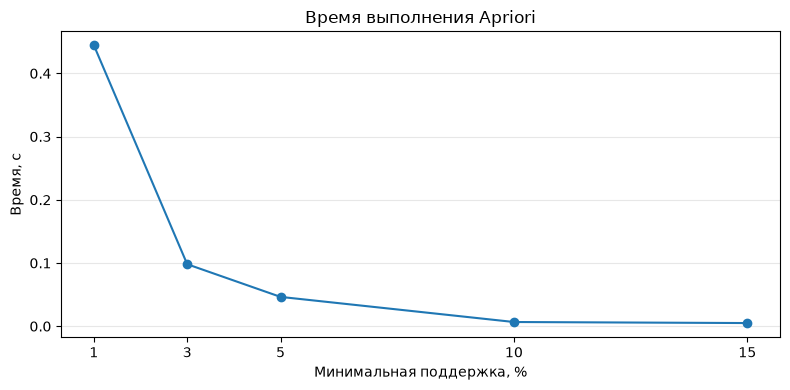

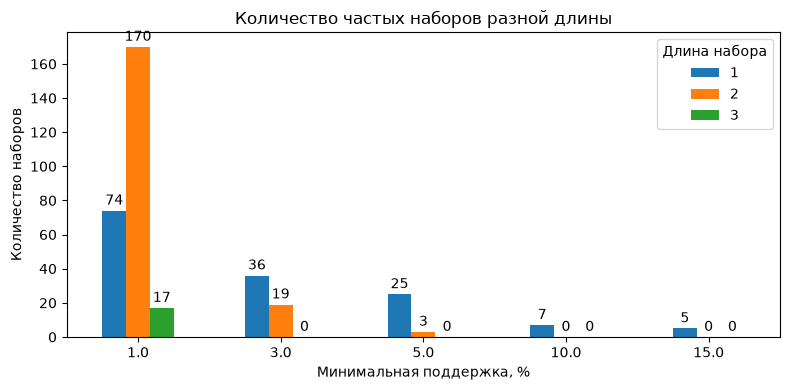

In [5]:
# Диаграмма 1: зависимость времени поиска от порога поддержки.
experiments.plot(x="Порог, %", y="Время, с", marker="o", legend=False,
                 figsize=(8, 4), title="Время выполнения Apriori",
                 xlabel="Минимальная поддержка, %", ylabel="Время, с")
plt.xticks([p * 100 for p in thresholds])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Диаграмма 2: количество наборов каждой длины при разных порогах.
ax = length_counts.plot(kind="bar", rot=0, figsize=(8, 4),
                        title="Количество частых наборов разной длины",
                        xlabel="Минимальная поддержка, %", ylabel="Количество наборов")
for bars in ax.containers:
    ax.bar_label(bars, padding=2)
plt.legend(title="Длина набора")
plt.tight_layout()
plt.show()
